<a href="https://colab.research.google.com/github/NabilaAdhelia/statistika-probabilitas-uniska/blob/main/Milestone3_Sampling_CI_StudentsPerformance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/drive/MyDrive/StudentsPerformance.csv")
print(f"Shape: {df.shape[0]} baris × {df.shape[1]} kolom")
df.head()

Shape: 1000 baris × 8 kolom


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
# Rename kolom agar mudah dipanggil
df = df.rename(columns={
    'race/ethnicity': 'race',
    'parental level of education': 'parent_edu',
    'test preparation course': 'test_prep',
    'math score': 'math',
    'reading score': 'reading',
    'writing score': 'writing'
})

print("=== DATA TYPES ===")
print(df.dtypes)
print("\n=== MISSING VALUES ===")
print(df.isnull().sum())
print(f"\n=== DUPLIKAT === {df.duplicated().sum()}")
print("\n=== DESCRIBE NUMERIK ===")
display(df.describe().round(2))
print("\n=== DISTRIBUSI KATEGORIKAL ===")
for col in ['gender', 'race', 'parent_edu', 'lunch', 'test_prep']:
    print(f"\n{col}:")
    print(df[col].value_counts())

=== DATA TYPES ===
gender        object
race          object
parent_edu    object
lunch         object
test_prep     object
math           int64
reading        int64
writing        int64
dtype: object

=== MISSING VALUES ===
gender        0
race          0
parent_edu    0
lunch         0
test_prep     0
math          0
reading       0
writing       0
dtype: int64

=== DUPLIKAT === 0

=== DESCRIBE NUMERIK ===


,math,reading,writing
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00



=== DISTRIBUSI KATEGORIKAL ===

gender:
gender
female    518
male      482
Name: count, dtype: int64

race:
race
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parent_edu:
parent_edu
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch:
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

test_prep:
test_prep
none         642
completed    358
Name: count, dtype: int64


In [6]:
numeric_cols = ['math', 'reading', 'writing']

central = pd.DataFrame({
    'Mean': df[numeric_cols].mean().round(2),
    'Median': df[numeric_cols].median().round(2),
    'Modus': df[numeric_cols].mode().iloc[0],
    'Diff (Mean-Median)': (df[numeric_cols].mean() - df[numeric_cols].median()).round(2),
})
print(central)

print("\nINTERPRETASI DISTRIBUSI:")
for col in numeric_cols:
    diff = (df[col].mean() - df[col].median()) / df[col].median() * 100
    if abs(diff) < 2:
        shape = "SYMMETRIC (dekat Normal)"
    elif diff > 0:
        shape = f"RIGHT-SKEWED (mean {diff:.1f}% > median)"
    else:
        shape = f"LEFT-SKEWED (mean {diff:.1f}% < median)"
    print(f"  {col:<10}: {shape}")

          Mean  Median  Modus  Diff (Mean-Median)
math     66.09    66.0     65                0.09
reading  69.17    70.0     72               -0.83
writing  68.05    69.0     74               -0.95

INTERPRETASI DISTRIBUSI:
  math      : SYMMETRIC (dekat Normal)
  reading   : SYMMETRIC (dekat Normal)
  writing   : SYMMETRIC (dekat Normal)


In [7]:
dispersion = pd.DataFrame({
    'Range': df[numeric_cols].max() - df[numeric_cols].min(),
    'Variance': df[numeric_cols].var().round(2),
    'Std Dev': df[numeric_cols].std().round(2),
    'Q1': df[numeric_cols].quantile(0.25),
    'Q3': df[numeric_cols].quantile(0.75),
    'IQR': df[numeric_cols].quantile(0.75) - df[numeric_cols].quantile(0.25),
    'CV (%)': (df[numeric_cols].std() / df[numeric_cols].mean() * 100).round(2),
})
print(dispersion)

print("\n=== DETEKSI OUTLIER (IQR method) ===")
for col in numeric_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    print(f"  {col:<10}: {n_out} outlier (<{Q1-1.5*IQR:.1f} atau >{Q3+1.5*IQR:.1f})")

         Range  Variance  Std Dev     Q1    Q3    IQR  CV (%)
math       100    229.92    15.16  57.00  77.0  20.00   22.94
reading     83    213.17    14.60  59.00  79.0  20.00   21.11
writing     90    230.91    15.20  57.75  79.0  21.25   22.33

=== DETEKSI OUTLIER (IQR method) ===
  math      : 8 outlier (<27.0 atau >107.0)
  reading   : 6 outlier (<29.0 atau >109.0)
  writing   : 5 outlier (<25.9 atau >110.9)


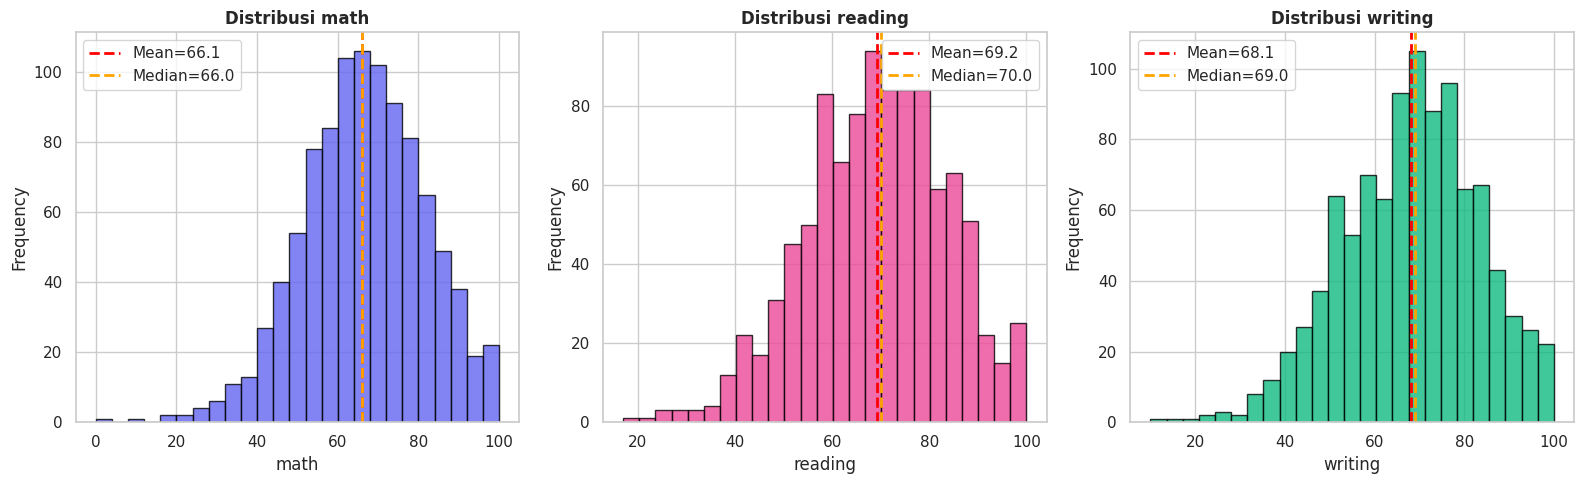

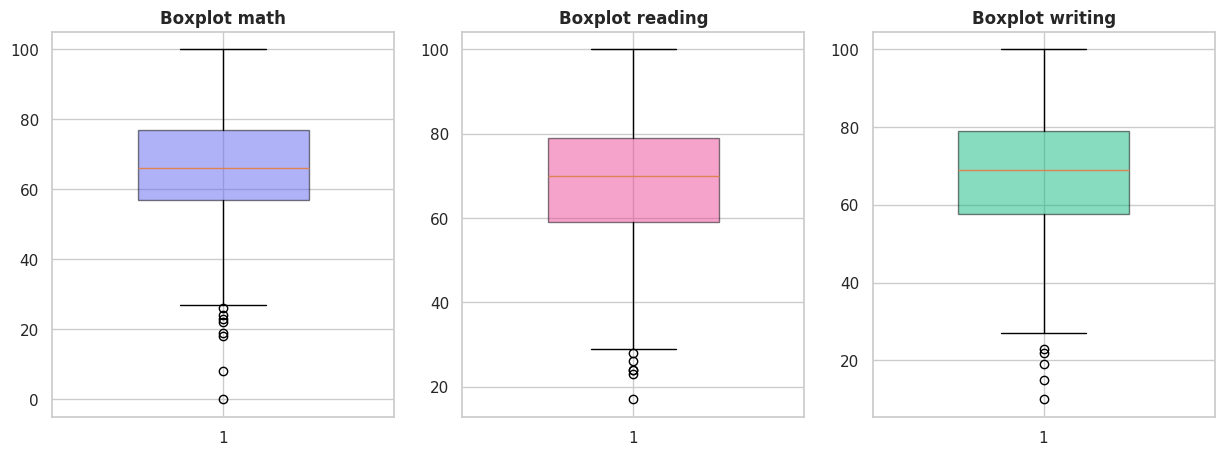

In [8]:
numeric_cols = ['math', 'reading', 'writing']
df['avg_score'] = df[numeric_cols].mean(axis=1).round(2)
colors = ['#6366F1', '#EC4899', '#10B981']

# Histogram + garis mean/median
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, color in zip(axes, numeric_cols, colors):
    ax.hist(df[col], bins=25, color=color, edgecolor='black', alpha=0.8)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean={df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='orange', linestyle='--', linewidth=2, label=f'Median={df[col].median():.1f}')
    ax.set_title(f'Distribusi {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()
plt.tight_layout()
plt.show()

# Boxplot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col, color in zip(axes, numeric_cols, colors):
    bp = ax.boxplot(df[col], patch_artist=True, widths=0.5)
    bp['boxes'][0].set_facecolor(color)
    bp['boxes'][0].set_alpha(0.5)
    ax.set_title(f'Boxplot {col}', fontweight='bold')

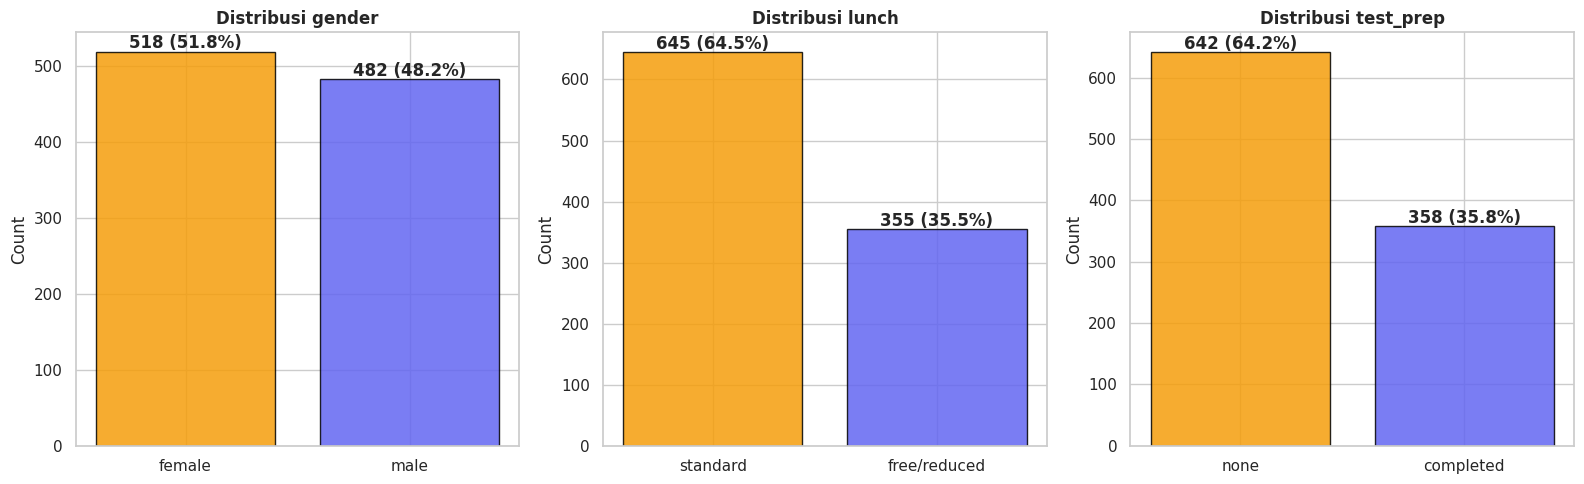

In [9]:
# Countplot kategorikal
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['gender', 'lunch', 'test_prep']):
    counts = df[col].value_counts()
    bars = ax.bar(counts.index, counts.values, color=['#F59E0B', '#6366F1'],
                  edgecolor='black', alpha=0.85)
    ax.set_title(f'Distribusi {col}', fontweight='bold')
    ax.set_ylabel('Count')
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                f'{val} ({val/len(df)*100:.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

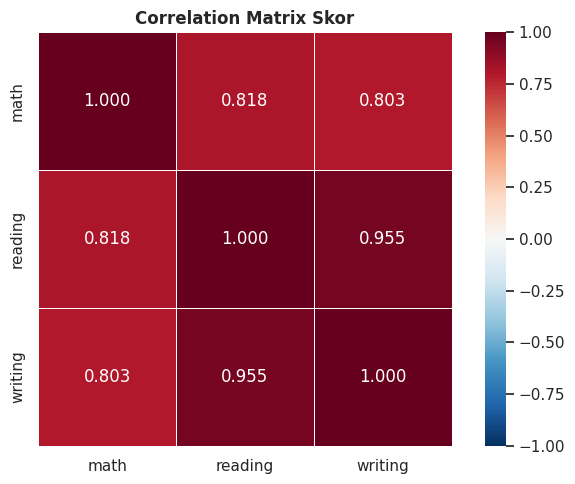

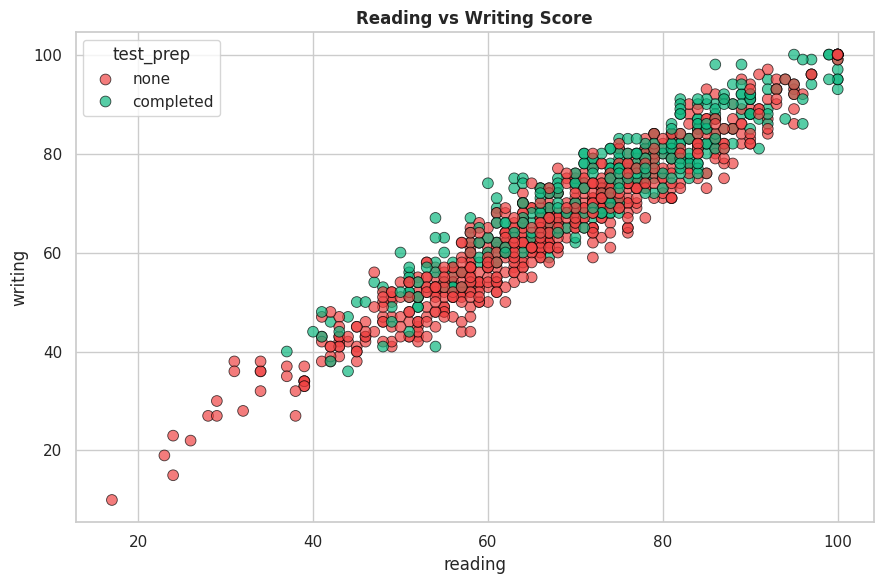

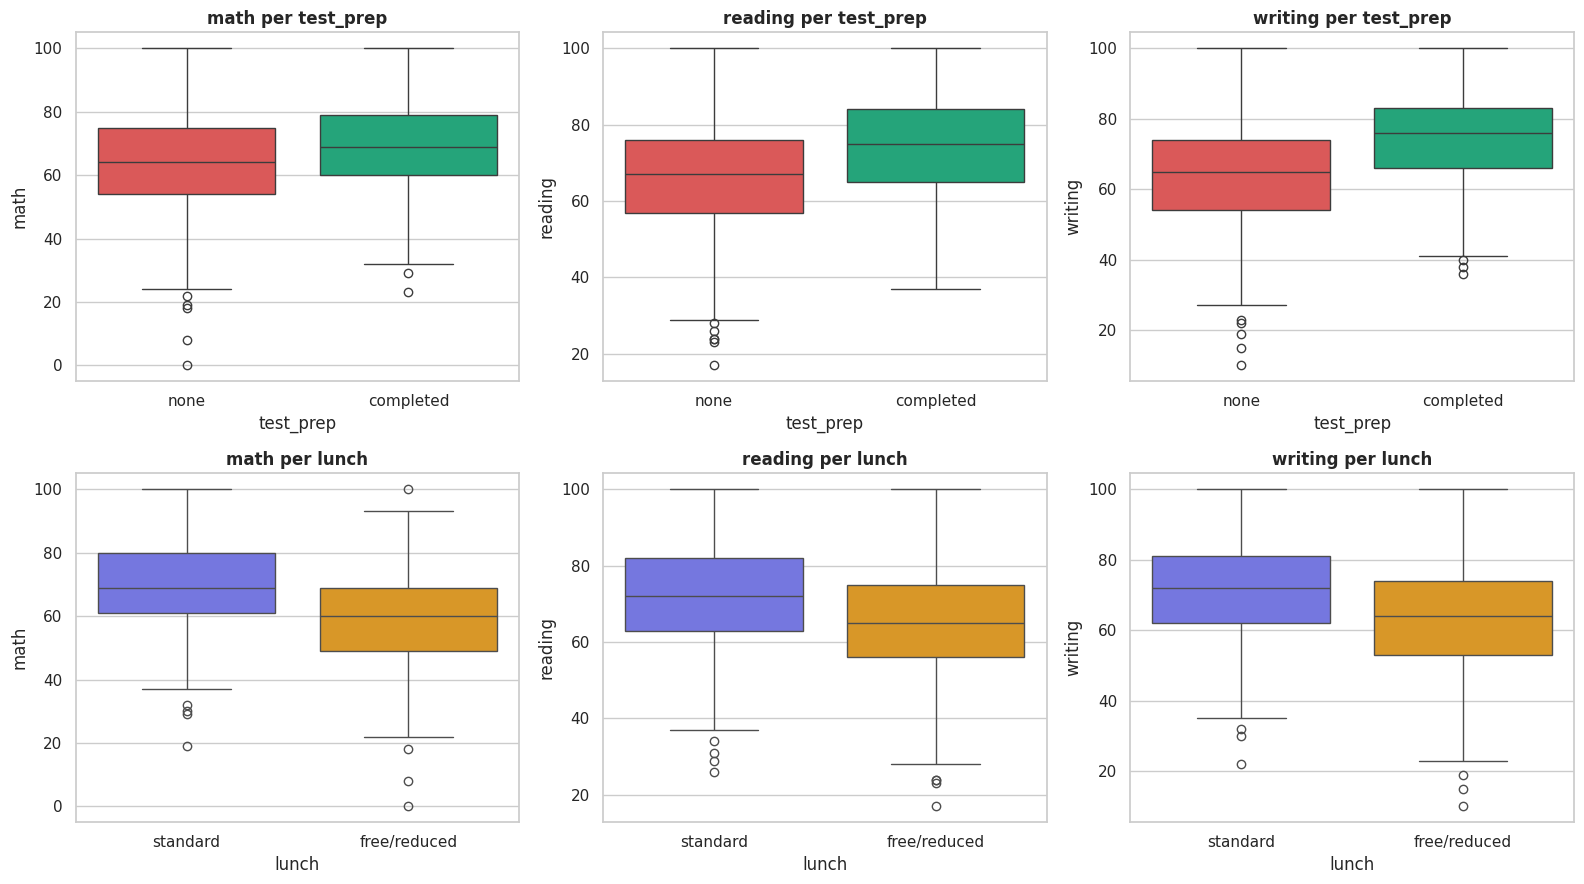

In [10]:
# Heatmap korelasi
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True)
ax.set_title('Correlation Matrix Skor', fontweight='bold')
plt.tight_layout()
plt.show()

# Scatter: reading vs writing, warna per test_prep
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x='reading', y='writing', hue='test_prep',
                palette={'none': '#EF4444', 'completed': '#10B981'},
                s=60, alpha=0.7, edgecolor='black', ax=ax)
ax.set_title('Reading vs Writing Score', fontweight='bold')
plt.tight_layout()
plt.show()

# Grouped boxplot: skor per test_prep dan per lunch
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='test_prep', y=col, hue='test_prep', legend=False,
                palette={'none': '#EF4444', 'completed': '#10B981'}, ax=axes[0, j])
    axes[0, j].set_title(f'{col} per test_prep', fontweight='bold')
    sns.boxplot(data=df, x='lunch', y=col, hue='lunch', legend=False,
                palette={'standard': '#6366F1', 'free/reduced': '#F59E0B'}, ax=axes[1, j])
    axes[1, j].set_title(f'{col} per lunch', fontweight='bold')
plt.tight_layout()
plt.show()

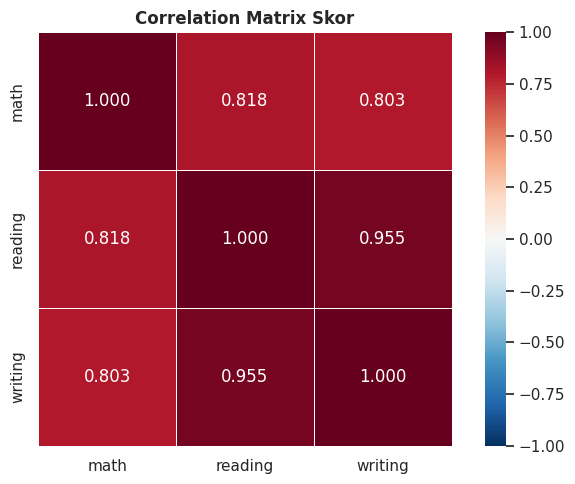

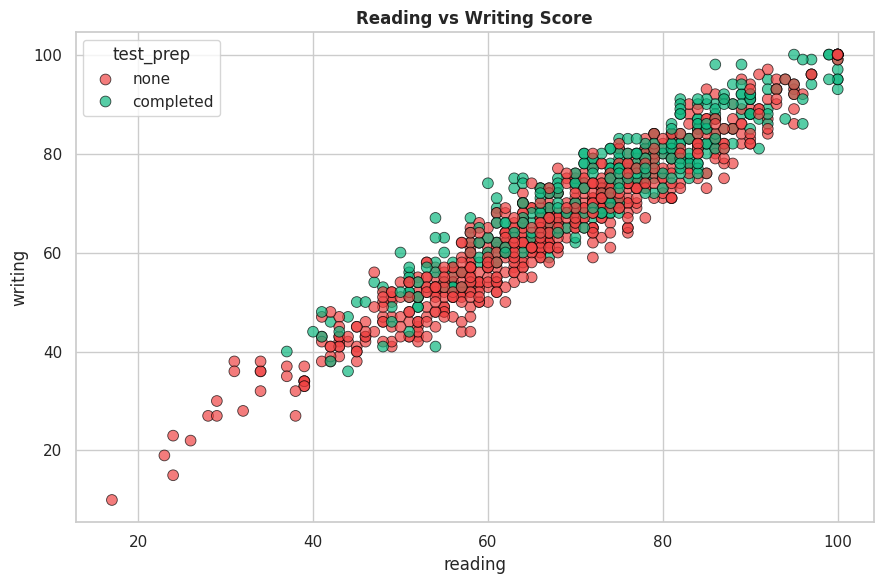

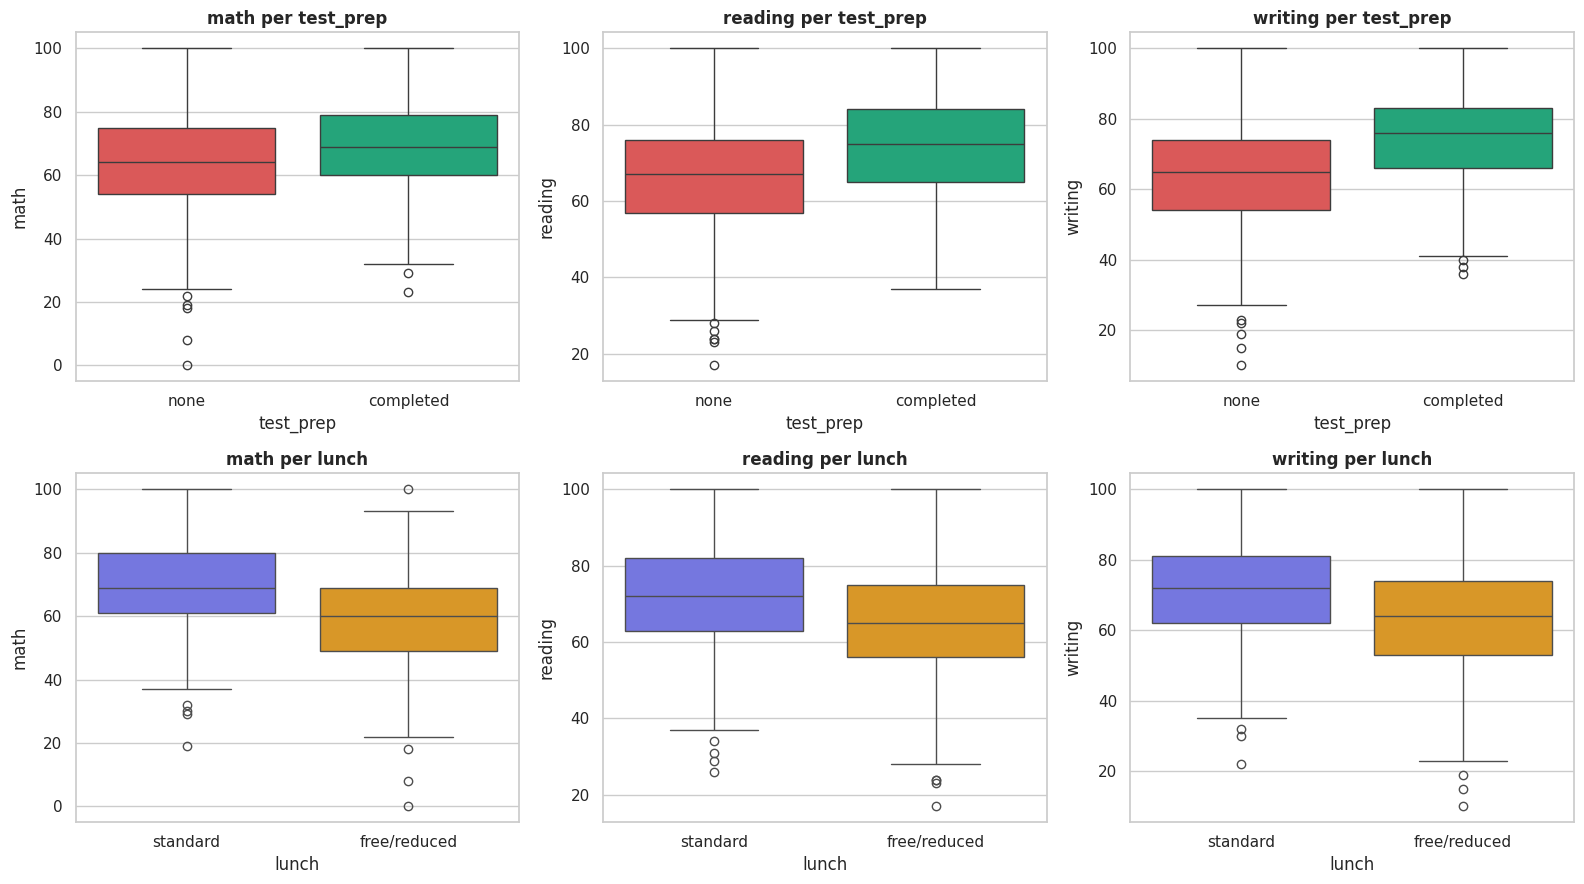

In [11]:
import os
os.makedirs('images', exist_ok=True)
numeric_cols = ['math', 'reading', 'writing']

# 1. Heatmap
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5, square=True)
ax.set_title('Correlation Matrix Skor', fontweight='bold')
plt.tight_layout()
plt.savefig('images/heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Scatter reading vs writing
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x='reading', y='writing', hue='test_prep',
                palette={'none': '#EF4444', 'completed': '#10B981'},
                s=60, alpha=0.7, edgecolor='black', ax=ax)
ax.set_title('Reading vs Writing Score', fontweight='bold')
plt.tight_layout()
plt.savefig('images/scatter.png', dpi=150, bbox_inches='tight')
plt.show()

# 3. Boxplot per kelompok
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x='test_prep', y=col, hue='test_prep', legend=False,
                palette={'none': '#EF4444', 'completed': '#10B981'}, ax=axes[0, j])
    axes[0, j].set_title(f'{col} per test_prep', fontweight='bold')
    sns.boxplot(data=df, x='lunch', y=col, hue='lunch', legend=False,
                palette={'standard': '#6366F1', 'free/reduced': '#F59E0B'}, ax=axes[1, j])
    axes[1, j].set_title(f'{col} per lunch', fontweight='bold')
plt.tight_layout()
plt.savefig('images/boxplot_kelompok.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
!zip -r images.zip images
from google.colab import files
files.download('images.zip')

  adding: images/ (stored 0%)
  adding: images/boxplot_kelompok.png (deflated 25%)
  adding: images/scatter.png (deflated 3%)
  adding: images/heatmap.png (deflated 11%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
print("=== RATA-RATA SKOR per test_prep ===")
print(df.groupby('test_prep')[numeric_cols].mean().round(2))
print("\n=== RATA-RATA SKOR per lunch ===")
print(df.groupby('lunch')[numeric_cols].mean().round(2))
print("\n=== RATA-RATA SKOR per gender ===")
print(df.groupby('gender')[numeric_cols].mean().round(2))
print("\n=== RATA-RATA avg_score per parent_edu ===")
print(df.groupby('parent_edu')['avg_score'].mean().round(2).sort_values())

=== RATA-RATA SKOR per test_prep ===
            math  reading  writing
test_prep                         
completed  69.70    73.89    74.42
none       64.08    66.53    64.50

=== RATA-RATA SKOR per lunch ===
               math  reading  writing
lunch                                
free/reduced  58.92    64.65    63.02
standard      70.03    71.65    70.82

=== RATA-RATA SKOR per gender ===
         math  reading  writing
gender                         
female  63.63    72.61    72.47
male    68.73    65.47    63.31

=== RATA-RATA avg_score per parent_edu ===
parent_edu
high school           63.10
some high school      65.11
some college          68.48
associate's degree    69.57
bachelor's degree     71.92
master's degree       73.60
Name: avg_score, dtype: float64


In [14]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

order = ['some high school', 'high school', 'some college',
         "associate's degree", "bachelor's degree", "master's degree"]
avg_edu = df.groupby('parent_edu')['avg_score'].mean().reindex(order).round(2)

fig = make_subplots(rows=1, cols=2,
                    subplot_titles=('Reading vs Writing Score',
                                    'Rata-rata Skor per Pendidikan Orang Tua'))

for prep, color in [('none', '#EF4444'), ('completed', '#10B981')]:
    sub = df[df['test_prep'] == prep]
    fig.add_trace(go.Scatter(x=sub['reading'], y=sub['writing'], mode='markers',
                             name=f'Test prep: {prep}',
                             marker=dict(color=color, opacity=0.6)), row=1, col=1)

fig.add_trace(go.Bar(x=avg_edu.index, y=avg_edu.values,
                     marker_color='#6366F1', showlegend=False), row=1, col=2)

fig.update_xaxes(title_text='Reading', row=1, col=1)
fig.update_yaxes(title_text='Writing', row=1, col=1)
fig.update_yaxes(title_text='Rata-rata skor', row=1, col=2)
fig.update_layout(height=500, width=1100, title_text='Students Performance Dashboard')
fig.show()

## Insight

1. **Data bersih dan distribusi simetris.** Tidak ada missing value atau duplikat pada 1000 baris. Mean dan median ketiga skor hampir sama (math 66,09 vs 66,0), dan semua outlier ada di sisi bawah (math 8, reading 6, writing 5).

2. **Test prep berkaitan dengan skor lebih tinggi.** Siswa yang menyelesaikan test prep unggul di semua mata ujian: math 69,70 vs 64,08, reading 73,89 vs 66,53, writing 74,42 vs 64,50. Hanya 35,8% siswa yang mengikutinya.

3. **Tipe makan siang berkaitan dengan skor.** Siswa lunch standard unggul atas free/reduced: math 70,03 vs 58,92 (selisih terbesar), reading 71,65 vs 64,65, writing 70,82 vs 63,02. Ini korelasi, bukan sebab-akibat.

4. **Pola gender berbeda antar mata ujian.** Perempuan lebih tinggi di reading (72,61 vs 65,47) dan writing (72,47 vs 63,31), sedangkan laki-laki lebih tinggi di math (68,73 vs 63,63).

5. **Korelasi antar skor kuat.** Reading–writing 0,955, math–reading 0,818, math–writing 0,803. Rata-rata skor juga naik seiring pendidikan orang tua, dari 63,10 (high school) ke 73,60 (master's degree).

## Hipotesis untuk Milestone 2 (Modul 10)

- **H1 (t-test independen):** Rata-rata skor writing siswa yang menyelesaikan test prep berbeda dari yang tidak mengikutinya.
- **H2 (t-test independen):** Rata-rata skor math siswa dengan lunch standard berbeda dari free/reduced.
- **H3 (ANOVA):** Rata-rata skor rata-rata (avg_score) berbeda antar tingkat pendidikan orang tua.

Populasi: n = 1000, mean = 68.05, std = 15.19, skewness = -0.29


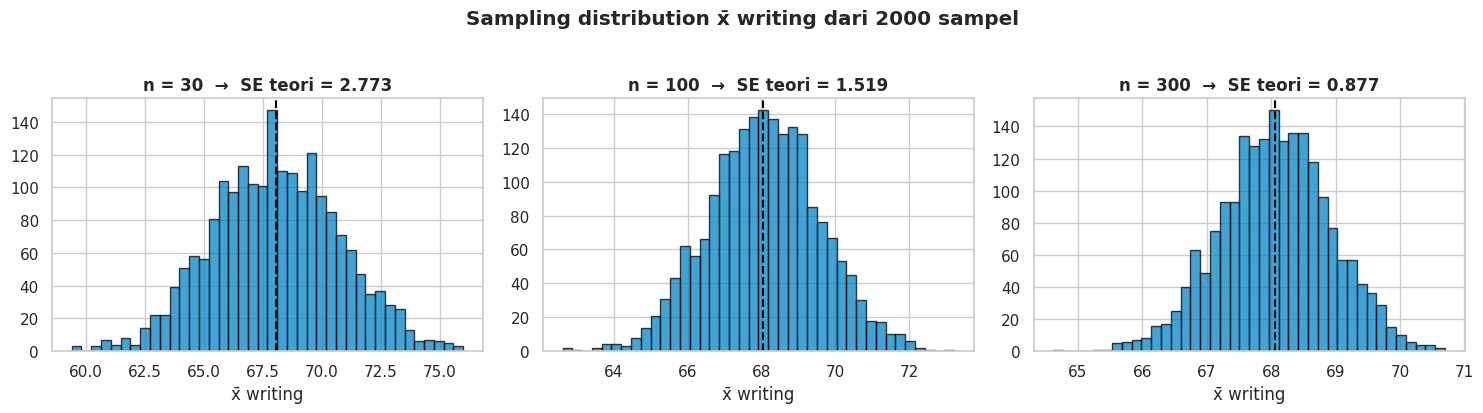

  n  SE empiris  SE teori
 30       2.714     2.773
100       1.506     1.519
300       0.864     0.877

💡 n naik → SE turun sebesar √n. SE empiris harus mendekati SE teori (σ/√n).


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
ALPHA = 0.05

metric = 'writing'
group_col, g1, g2 = 'test_prep', 'completed', 'none'

# ---------- 1. Sampling distribution metrik utama ----------
pop = df[metric].dropna().values
print(f"Populasi: n = {len(pop)}, mean = {pop.mean():.2f}, std = {pop.std():.2f}, skewness = {stats.skew(pop):.2f}")

REPS = 2000
rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, [30, 100, 300]):
    means = rng.choice(pop, size=(REPS, n), replace=True).mean(axis=1)
    se_theory = pop.std() / np.sqrt(n)
    rows.append([n, means.std(), se_theory])
    ax.hist(means, bins=40, color='#0284C7', edgecolor='black', alpha=0.75)
    ax.axvline(pop.mean(), color='black', ls='--')
    ax.set_title(f'n = {n}  →  SE teori = {se_theory:.3f}', fontweight='bold')
    ax.set_xlabel('x̄ writing')
plt.suptitle(f'Sampling distribution x̄ {metric} dari {REPS} sampel', y=1.03, fontweight='bold')
plt.tight_layout(); plt.show()

print(pd.DataFrame(rows, columns=['n', 'SE empiris', 'SE teori']).round(3).to_string(index=False))
print("\n💡 n naik → SE turun sebesar √n. SE empiris harus mendekati SE teori (σ/√n).")

=== CI 95% RATA-RATA writing - rumus (t) vs bootstrap ===
       grup    n  mean   SE  Rumus lo  Rumus hi  Boot lo  Boot hi
Semua siswa 1000 68.05 0.48     67.11     69.00    67.10    69.01
  completed  358 74.42 0.71     73.03     75.81    73.01    75.78
       none  642 64.50 0.59     63.34     65.67    63.34    65.65


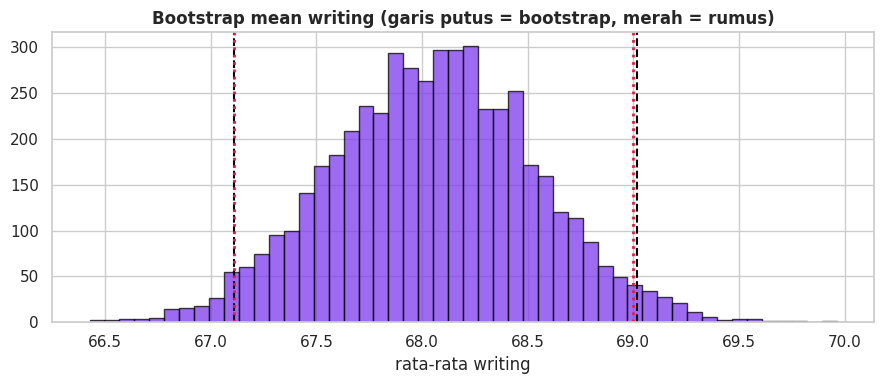

Rumus dan bootstrap hampir sama karena n besar dan data mendekati simetris.
Bootstrap lebih berguna untuk statistik tanpa rumus SE sederhana (median, rasio, persentil).


In [18]:
# ---------- 2. CI rumus vs bootstrap untuk rata-rata writing ----------
B_REPS = 5000

def ci_formula(x, alpha=ALPHA):
    n, m, s = len(x), x.mean(), x.std(ddof=1)
    se = s / np.sqrt(n)
    lo, hi = stats.t.interval(1 - alpha, df=n-1, loc=m, scale=se)
    return m, se, lo, hi

def ci_bootstrap(x, reps=B_REPS, alpha=ALPHA):
    boots = rng.choice(x, size=(reps, len(x)), replace=True).mean(axis=1)
    return np.percentile(boots, [alpha/2*100, (1-alpha/2)*100]), boots

x_all = df[metric].dropna().values
x1 = df.loc[df[group_col] == g1, metric].dropna().values
x2 = df.loc[df[group_col] == g2, metric].dropna().values

rows = []
for label, x in [('Semua siswa', x_all), (g1, x1), (g2, x2)]:
    m, se, flo, fhi = ci_formula(x)
    (blo, bhi), _ = ci_bootstrap(x)
    rows.append([label, len(x), m, se, flo, fhi, blo, bhi])

ci_tbl = pd.DataFrame(rows, columns=['grup', 'n', 'mean', 'SE', 'Rumus lo', 'Rumus hi', 'Boot lo', 'Boot hi'])
print(f"=== CI 95% RATA-RATA {metric} - rumus (t) vs bootstrap ===")
print(ci_tbl.round(2).to_string(index=False))

# Visualisasi bootstrap untuk semua siswa
(blo, bhi), boots = ci_bootstrap(x_all)
m, se, flo, fhi = ci_formula(x_all)
plt.figure(figsize=(9, 4))
plt.hist(boots, bins=50, color='#7C3AED', edgecolor='black', alpha=0.75)
for v in [blo, bhi]:
    plt.axvline(v, color='black', ls='--')
for v in [flo, fhi]:
    plt.axvline(v, color='#E11D48', ls=':', lw=2)
plt.title('Bootstrap mean writing (garis putus = bootstrap, merah = rumus)', fontweight='bold')
plt.xlabel('rata-rata writing')
plt.tight_layout()
plt.show()

print("Rumus dan bootstrap hampir sama karena n besar dan data mendekati simetris.")
print("Bootstrap lebih berguna untuk statistik tanpa rumus SE sederhana (median, rasio, persentil).")

=== SELISIH RATA-RATA writing: completed - none ===
  Mean completed = 74.42 (n=358), Mean none = 64.50 (n=642)
  Selisih = 9.91 poin, SE = 0.922
  CI 95% rumus (Welch) : [8.10, 11.72]
  CI 95% bootstrap     : [8.13, 11.69]
  Cohen's d = 0.69
  CI memuat 0? Tidak (selisih signifikan)


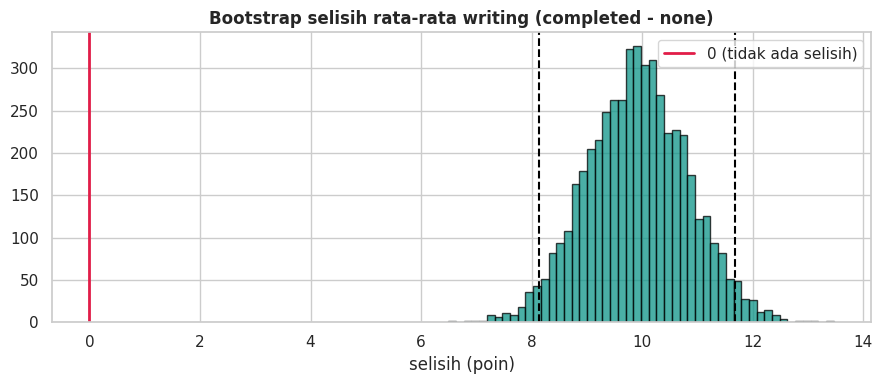

In [19]:
# ---------- 3. CI selisih rata-rata writing: completed - none ----------
def ci_diff_welch(a, b, alpha=ALPHA):
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    d = a.mean() - b.mean()
    se = np.sqrt(va + vb)
    dfw = (va + vb)**2 / (va**2 / (len(a) - 1) + vb**2 / (len(b) - 1))
    tcrit = stats.t.ppf(1 - alpha/2, dfw)
    return d, se, d - tcrit * se, d + tcrit * se

d, se, flo, fhi = ci_diff_welch(x1, x2)

boot_d = np.empty(5000)
for i in range(5000):
    boot_d[i] = rng.choice(x1, len(x1)).mean() - rng.choice(x2, len(x2)).mean()
blo, bhi = np.percentile(boot_d, [2.5, 97.5])

pooled_sd = np.sqrt(((len(x1) - 1) * x1.var(ddof=1) + (len(x2) - 1) * x2.var(ddof=1)) / (len(x1) + len(x2) - 2))
cohen_d = d / pooled_sd

print(f"=== SELISIH RATA-RATA {metric}: {g1} - {g2} ===")
print(f"  Mean {g1} = {x1.mean():.2f} (n={len(x1)}), Mean {g2} = {x2.mean():.2f} (n={len(x2)})")
print(f"  Selisih = {d:.2f} poin, SE = {se:.3f}")
print(f"  CI 95% rumus (Welch) : [{flo:.2f}, {fhi:.2f}]")
print(f"  CI 95% bootstrap     : [{blo:.2f}, {bhi:.2f}]")
print(f"  Cohen's d = {cohen_d:.2f}")
print(f"  CI memuat 0? {'Ya' if flo <= 0 <= fhi else 'Tidak (selisih signifikan)'}")

plt.figure(figsize=(9, 4))
plt.hist(boot_d, bins=50, color='#0D9488', edgecolor='black', alpha=0.75)
plt.axvline(0, color='#E11D48', lw=2, label='0 (tidak ada selisih)')
for v in [blo, bhi]:
    plt.axvline(v, color='black', ls='--')
plt.title('Bootstrap selisih rata-rata writing (completed - none)', fontweight='bold')
plt.xlabel('selisih (poin)')
plt.legend()
plt.tight_layout()
plt.show()

Pooled SD = 14.44

=== SAMPLE SIZE PER GRUP (alpha=0.05, power=0.80) ===
  MDE 1 poin (Cohen's d = 0.07) -> n = 3,274 per grup
  MDE 2 poin (Cohen's d = 0.14) -> n = 819 per grup
  MDE 3 poin (Cohen's d = 0.21) -> n = 365 per grup
  MDE 5 poin (Cohen's d = 0.35) -> n = 132 per grup
  MDE 8 poin (Cohen's d = 0.55) -> n = 52 per grup

Data tersedia: completed = 358, none = 642
Power untuk mendeteksi MDE 3 poin = 88%
MDE terkecil (power 80%) = 2.67 poin (Cohen's d = 0.18)
Power untuk selisih teramati (9.91 poin) = 100%


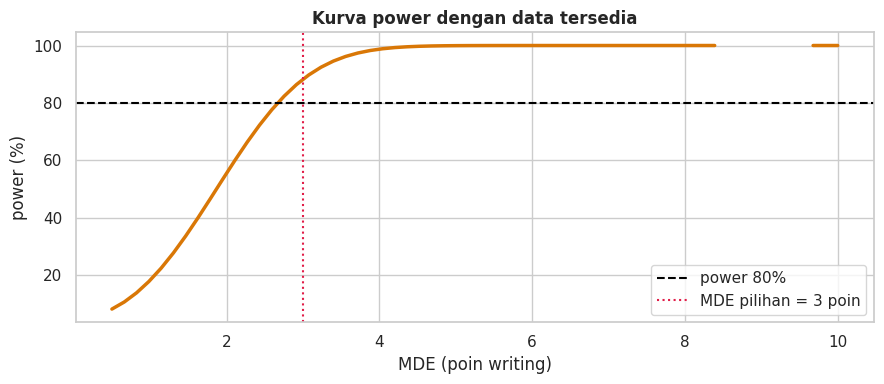

In [20]:
# ---------- 4. Power analysis untuk selisih rata-rata writing ----------
from statsmodels.stats.power import TTestIndPower

power = TTestIndPower()
n1, n2 = len(x1), len(x2)
pooled_sd = np.sqrt(((n1 - 1) * x1.var(ddof=1) + (n2 - 1) * x2.var(ddof=1)) / (n1 + n2 - 2))
print(f"Pooled SD = {pooled_sd:.2f}")

# (a) Sample size per grup untuk berbagai MDE (alpha=0.05, power=0.80, rasio 1:1)
print("\n=== SAMPLE SIZE PER GRUP (alpha=0.05, power=0.80) ===")
for mde in [1, 2, 3, 5, 8]:
    es = mde / pooled_sd
    n_need = power.solve_power(effect_size=es, alpha=ALPHA, power=0.80, ratio=1.0)
    print(f"  MDE {mde} poin (Cohen's d = {es:.2f}) -> n = {n_need:,.0f} per grup")

# (b) Power yang dicapai dengan data yang ada (n1=358, n2=642)
MDE = 3
es_mde = MDE / pooled_sd
achieved = power.solve_power(effect_size=es_mde, nobs1=n1, alpha=ALPHA, ratio=n2 / n1)
print(f"\nData tersedia: {g1} = {n1}, {g2} = {n2}")
print(f"Power untuk mendeteksi MDE {MDE} poin = {achieved:.0%}")

# (c) MDE terkecil yang bisa dideteksi dengan power 80% pada data yang ada
es_min = power.solve_power(nobs1=n1, alpha=ALPHA, power=0.80, ratio=n2 / n1)
print(f"MDE terkecil (power 80%) = {es_min * pooled_sd:.2f} poin (Cohen's d = {es_min:.2f})")

# (d) Power untuk selisih yang teramati
es_obs = d / pooled_sd
power_obs = power.solve_power(effect_size=es_obs, nobs1=n1, alpha=ALPHA, ratio=n2 / n1)
print(f"Power untuk selisih teramati ({d:.2f} poin) = {power_obs:.0%}")

# Kurva power vs MDE
mdes = np.linspace(0.5, 10, 60)
pw = [power.solve_power(effect_size=m / pooled_sd, nobs1=n1, alpha=ALPHA, ratio=n2 / n1) for m in mdes]
plt.figure(figsize=(9, 4))
plt.plot(mdes, np.array(pw) * 100, lw=2.5, color='#D97706')
plt.axhline(80, color='black', ls='--', label='power 80%')
plt.axvline(MDE, color='#E11D48', ls=':', label=f'MDE pilihan = {MDE} poin')
plt.xlabel('MDE (poin writing)')
plt.ylabel('power (%)')
plt.title('Kurva power dengan data tersedia', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

## Rekomendasi Keputusan (Ship or Not)

**Pertanyaan bisnis:** apakah program test preparation layak dilanjutkan/diperluas untuk meningkatkan skor writing siswa?

**Metrik utama:** rata-rata skor writing. **MDE pilihan:** 3 poin (selisih terkecil yang dianggap bermakna secara praktis).

**Bukti:**
- Rata-rata writing siswa completed = 74,42 (n = 358) dan none = 64,50 (n = 642).
- Selisih = 9,91 poin, CI 95% Welch [8,10; 11,72] dan CI bootstrap [8,13; 11,69]. Kedua CI tidak memuat 0.
- Batas bawah CI (8,10) berada jauh di atas MDE (3 poin), jadi selisihnya bukan hanya signifikan secara statistik tetapi juga bermakna secara praktis. Cohen's d = 0,69 (efek sedang menuju besar).
- Kecukupan data: dengan n yang tersedia, power untuk mendeteksi MDE 3 poin = 88% dan MDE terkecil yang terdeteksi pada power 80% = 2,67 poin. Data cukup untuk kesimpulan ini.

**Keputusan:** SHIP. Lanjutkan dan dorong siswa mengikuti program test preparation, karena siswa yang menyelesaikannya memiliki skor writing sekitar 8 sampai 12 poin lebih tinggi.

**Catatan risiko:**
1. **Bukan bukti kausal.** Data bersifat observasional, bukan eksperimen acak. Siswa yang mengikuti test prep mungkin memang lebih rajin atau punya latar belakang berbeda (self-selection), sehingga selisih belum tentu murni efek program.
2. **Faktor pengganggu belum dikendalikan** (misalnya pendidikan orang tua dan jenis lunch). Perlu analisis lanjutan atau uji acak kecil (pilot) sebelum memperluas program secara besar-besaran.
3. **Cakupan metrik.** Analisis hanya pada skor writing. Efek pada math dan reading belum diperiksa.
4. **Asal data.** Dataset publik (Kaggle) dengan 1.000 siswa dan cara pengumpulan yang tidak sepenuhnya jelas, sehingga generalisasi ke sekolah lain perlu hati-hati.
5. **Asumsi.** Distribusi writing sedikit miring ke kiri (skewness = -0,29),